- Instituto Tecnológico De Estudios Superiores de Monterrey
- Maestría en Inteligencia Artificial Aplicada (MSNA)
- Materia: Operaciones de Aprendizaje Automático
- Ejercicio Semana 4. Exploración de datos
-------------------------------------------------------------------------------------------------
- Alumno: Oscar Alfonso Valenzuela Muñoz
- No. Cuenta: A01840486
- Mail: A01840486@tec.mx

Fecha: 11-10-26

# Exploración de datos

Este notebook se conserva únicamente para la exploración del dataset. La carga, la limpieza, el entrenamiento y la evaluación del modelo se encuentran en `src/train.py`, que es el script que se ejecuta y registra en MLflow.

Dataset Seleccionado: Subramaniyan, M. (2023). Paddy Dataset [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55W3J.

### 1. Carga y descripción del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Cargar el dataset directamente desde el archivo zip
import zipfile
with zipfile.ZipFile('../data/paddy+dataset.zip', 'r') as z:
    with z.open('paddydataset.csv') as f:
        df = pd.read_csv(f)

df.head()

,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,...,Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75.0,dry,120,6,240,...,SW,W,NNW,WSW,72.0,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75.0,wet,120,6,240,...,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75.0,dry,120,6,240,...,ENE,NE,NNE,W,85.0,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75.0,wet,120,6,240,...,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75.0,dry,120,6,240,...,SSE,W,SW,NW,72.7,91,83,81,600,34044


Descripción de la estructura del dataset:

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2789 entries, 0 to 2788
Data columns (total 45 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Hectares                            2789 non-null   int64  
 1   Agriblock                           2789 non-null   str    
 2   Variety                             2789 non-null   str    
 3   Soil Types                          2789 non-null   str    
 4   Seedrate(in Kg)                     2789 non-null   int64  
 5   LP_Mainfield(in Tonnes)             2789 non-null   float64
 6   Nursery                             2789 non-null   str    
 7   Nursery area (Cents)                2789 non-null   int64  
 8   LP_nurseryarea(in Tonnes)           2789 non-null   int64  
 9   DAP_20days                          2789 non-null   int64  
 10  Weed28D_thiobencarb                 2789 non-null   int64  
 11  Urea_40Days                         2789 non-null   fl

### 2. Análisis Exploratorio (EDA)

In [3]:
# Estadísticas descriptivas
df.describe()

,Hectares,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,...,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
count,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,...,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000,2789.000000
mean,3.717461,92.936536,46.468268,74.349229,3.717461,148.698458,7.434923,100.854729,38.587250,55.761922,...,7.233417,8.512729,8.172822,9.449265,76.256938,87.594120,85.160272,83.859448,335.510936,22517.728935
std,1.437777,35.944420,17.972210,28.755536,1.437777,57.511072,2.875554,39.006885,14.924123,21.566652,...,2.566549,3.203679,1.993596,2.516664,8.001361,6.776736,3.492529,3.134875,134.314772,9199.661393
min,1.000000,25.000000,12.500000,20.000000,1.000000,40.000000,2.000000,27.130000,10.380000,15.000000,...,4.000000,4.000000,4.000000,6.000000,64.600000,78.000000,81.000000,79.000000,80.000000,5410.000000
25%,3.000000,75.000000,37.500000,60.000000,3.000000,120.000000,6.000000,81.390000,31.140000,45.000000,...,4.000000,6.000000,8.000000,6.000000,72.000000,80.000000,83.000000,81.000000,240.000000,16389.000000
50%,4.000000,100.000000,50.000000,80.000000,4.000000,160.000000,8.000000,108.520000,41.520000,60.000000,...,8.000000,10.000000,8.000000,10.000000,72.700000,91.000000,84.000000,84.000000,360.000000,24636.000000
75%,5.000000,125.000000,62.500000,100.000000,5.000000,200.000000,10.000000,135.650000,51.900000,75.000000,...,10.000000,12.000000,10.000000,12.000000,85.000000,95.000000,88.000000,87.000000,450.000000,31035.000000
max,6.000000,150.000000,75.000000,120.000000,6.000000,240.000000,12.000000,162.780000,62.280000,90.000000,...,10.000000,12.000000,10.000000,12.000000,88.500000,96.000000,92.000000,88.000000,600.000000,38814.000000


Visualización de la distribución de la variable objetivo y la relación con la variedad del cultivo.

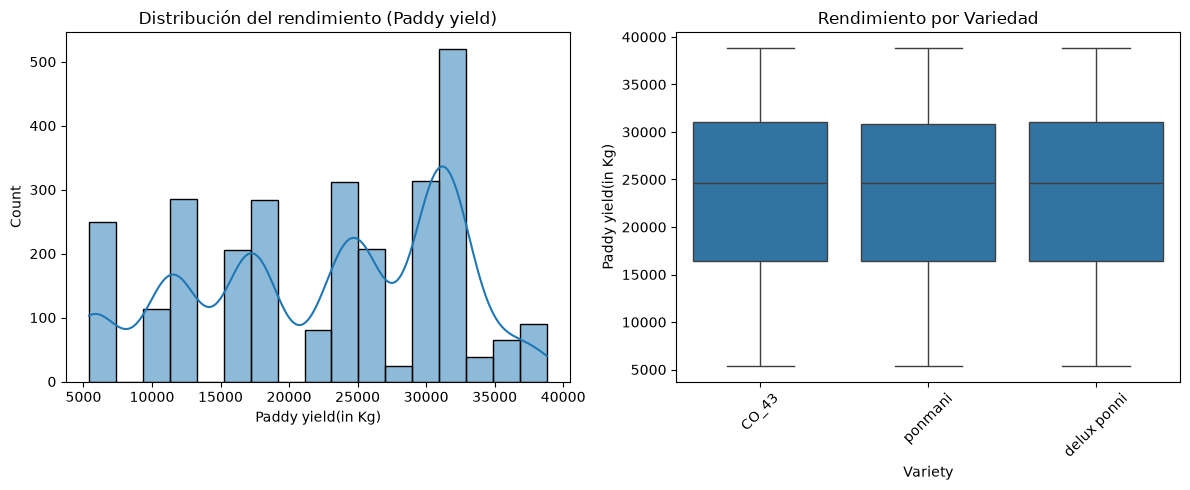

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de la variable objetivo
sns.histplot(df['Paddy yield(in Kg)'], kde=True, ax=ax[0])
ax[0].set_title('Distribución del rendimiento (Paddy yield)')

# Boxplot de Variedad vs Rendimiento
sns.boxplot(x='Variety', y='Paddy yield(in Kg)', data=df, ax=ax[1])
ax[1].set_title('Rendimiento por Variedad')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Las visualizaciones muestran la distribución de la variable dependiente y cómo varía el rendimiento de acuerdo con el tipo de variedad sembrada, proporcionando información clave sobre posibles segmentaciones del modelo.

### 3. Calidad de los datos

In [5]:
# Verificación de valores nulos y duplicados
nulos = df.isnull().sum()[df.isnull().sum() > 0]
duplicados = df.duplicated().sum()

print("Valores nulos:", nulos if not nulos.empty else "Ninguno")
print("Duplicados encontrados:", duplicados)

Valores nulos: Ninguno
Duplicados encontrados: 451


No se detectaron valores nulos, pero sí registros duplicados. Su eliminación se realiza en la función `preprocess_data` de `src/train.py` para que el tratamiento quede en un solo lugar.

In [6]:
# Identificación de valores atípicos en la variable objetivo mediante el rango intercuartílico (IQR)
objetivo = 'Paddy yield(in Kg)'
q1 = df[objetivo].quantile(0.25)
q3 = df[objetivo].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
atipicos = df[(df[objetivo] < limite_inf) | (df[objetivo] > limite_sup)]

print(f"Límites IQR: {limite_inf:.0f} a {limite_sup:.0f} kg")
print(f"Registros fuera de los límites: {len(atipicos)}")

Límites IQR: -5580 a 53004 kg
Registros fuera de los límites: 0


Los registros fuera de los límites se descartan durante el preprocesamiento del script de entrenamiento. Aquí solo se cuantifican para entender su peso dentro del dataset.

### 4. Relación entre superficie y rendimiento

La variable objetivo mide kilos totales por parcela, por lo que conviene revisar cuánto depende de la superficie sembrada.

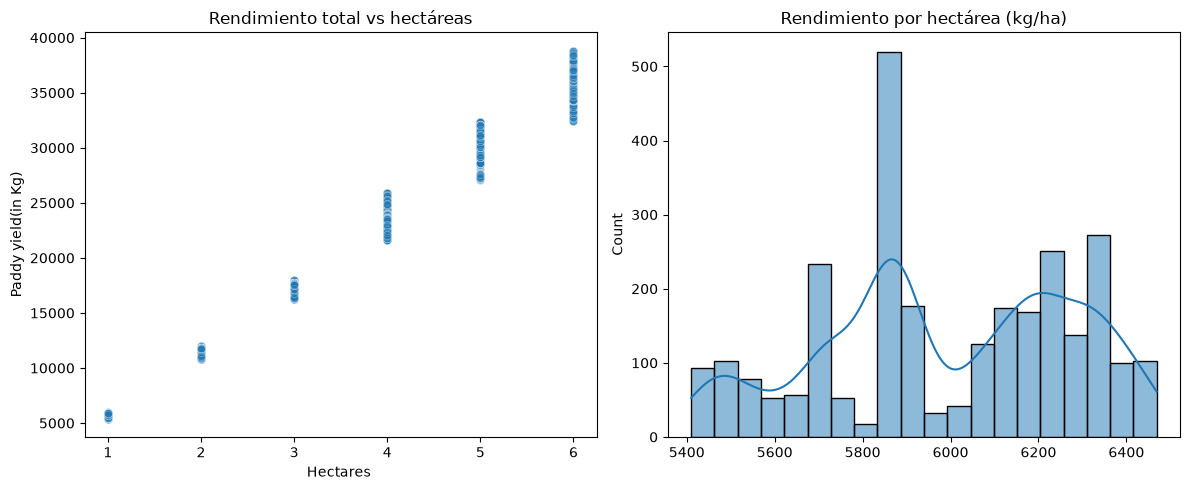

Correlación hectáreas vs rendimiento: 0.9946


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x='Hectares ', y=objetivo, data=df, alpha=0.4, ax=ax[0])
ax[0].set_title('Rendimiento total vs hectáreas')

sns.histplot(df[objetivo] / df['Hectares '], kde=True, ax=ax[1])
ax[1].set_title('Rendimiento por hectárea (kg/ha)')

plt.tight_layout()
plt.show()

print("Correlación hectáreas vs rendimiento:", round(df['Hectares '].corr(df[objetivo]), 4))

La correlación entre hectáreas y rendimiento total es cercana a 1 y el rendimiento por hectárea varía poco. Esto significa que la superficie explica casi toda la variación de la variable objetivo, lo que debe tomarse en cuenta al interpretar las métricas del modelo.